In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

customers = pd.read_csv(
    "../Datasets/Financial_Customers.csv"
)

customers.head()

,customer_id,signup_date,segment,industry,country,plan,mrr,contract_length,number_of_users,support_tickets,...,churn_date,is_churned,lifetime_months,total_revenue,clv,last_transaction_date,recency_days,transaction_count,avg_transaction_value,cohort_month
0,CUST_000001,2023-01-31,Startup,Healthcare,Other,Basic,49,24,3,2,...,NaN,0.0,23.3,1194.63,1194.63,2024-12-28,3,24,49.776250,2023-01
1,CUST_000002,2023-12-30,Startup,Retail,USA,Basic,49,12,4,1,...,NaN,0.0,12.2,676.89,676.89,2024-12-29,2,13,52.068462,2023-12
2,CUST_000003,2022-05-10,Small Business,Retail,Other,Professional,149,12,8,1,...,2024-03-22,1.0,22.7,3470.20,3470.20,2024-03-10,296,23,150.878261,2022-05
3,CUST_000004,2023-07-18,Startup,Retail,USA,Business,399,1,1,3,...,NaN,0.0,17.7,7107.69,7107.69,2024-12-18,13,18,394.871667,2023-07
4,CUST_000005,2023-02-04,Startup,Technology,USA,Business,399,12,2,0,...,NaN,0.0,23.2,9839.84,9839.84,2024-12-04,27,23,427.819130,2023-02


In [3]:
customers.shape

(5000, 22)

In [4]:
customers.columns.tolist()

['customer_id',
 'signup_date',
 'segment',
 'industry',
 'country',
 'plan',
 'mrr',
 'contract_length',
 'number_of_users',
 'support_tickets',
 'usage_score',
 'nps_score',
 'churn_date',
 'is_churned',
 'lifetime_months',
 'total_revenue',
 'clv',
 'last_transaction_date',
 'recency_days',
 'transaction_count',
 'avg_transaction_value',
 'cohort_month']

In [5]:
customers.dtypes

customer_id               object
signup_date               object
segment                   object
industry                  object
country                   object
plan                      object
mrr                        int64
contract_length            int64
number_of_users            int64
support_tickets            int64
usage_score                int64
nps_score                  int64
churn_date                object
is_churned               float64
lifetime_months          float64
total_revenue            float64
clv                      float64
last_transaction_date     object
recency_days               int64
transaction_count          int64
avg_transaction_value    float64
cohort_month              object
dtype: object

In [6]:
customers.describe()

,mrr,contract_length,number_of_users,support_tickets,usage_score,nps_score,is_churned,lifetime_months,total_revenue,clv,recency_days,transaction_count,avg_transaction_value
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,265.57000,13.695000,38.106200,2.023800,64.499400,28.371600,0.131200,26.944940,7166.833910,7166.833910,108.697600,27.043600,270.394273
std,286.75317,11.031986,90.640461,1.436261,19.177892,38.396739,0.337653,17.484849,10101.575347,10101.575347,286.277569,17.226545,292.125380
min,49.00000,1.000000,1.000000,0.000000,0.000000,-100.000000,0.000000,0.000000,44.540000,44.540000,1.000000,1.000000,44.540000
25%,49.00000,1.000000,3.000000,1.000000,51.000000,2.000000,0.000000,11.700000,1253.485000,1253.485000,9.000000,12.000000,50.317708
50%,149.00000,12.000000,7.000000,2.000000,65.000000,29.000000,0.000000,24.000000,2907.190000,2907.190000,18.000000,24.000000,151.275981
75%,399.00000,24.000000,26.000000,3.000000,78.000000,56.000000,0.000000,41.700000,8348.680000,8348.680000,27.000000,42.000000,403.708208
max,999.00000,36.000000,499.000000,9.000000,100.000000,100.000000,1.000000,60.900000,61514.520000,61514.520000,1717.000000,60.000000,1182.192000


In [7]:
print(customers["plan"].value_counts())

print(customers["segment"].value_counts())

print(customers["is_churned"].value_counts())


plan
Basic           1785
Professional    1444
Business        1240
Enterprise       531
Name: count, dtype: int64
segment
Small Business    1993
Mid-Market        1258
Startup           1236
Enterprise         513
Name: count, dtype: int64
is_churned
0.0    4344
1.0     656
Name: count, dtype: int64


In [8]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            5000 non-null   object 
 1   signup_date            5000 non-null   object 
 2   segment                5000 non-null   object 
 3   industry               5000 non-null   object 
 4   country                5000 non-null   object 
 5   plan                   5000 non-null   object 
 6   mrr                    5000 non-null   int64  
 7   contract_length        5000 non-null   int64  
 8   number_of_users        5000 non-null   int64  
 9   support_tickets        5000 non-null   int64  
 10  usage_score            5000 non-null   int64  
 11  nps_score              5000 non-null   int64  
 12  churn_date             656 non-null    object 
 13  is_churned             5000 non-null   float64
 14  lifetime_months        5000 non-null   float64
 15  tota

In [9]:
customers.isnull().sum()

customer_id                 0
signup_date                 0
segment                     0
industry                    0
country                     0
plan                        0
mrr                         0
contract_length             0
number_of_users             0
support_tickets             0
usage_score                 0
nps_score                   0
churn_date               4344
is_churned                  0
lifetime_months             0
total_revenue               0
clv                         0
last_transaction_date       0
recency_days                0
transaction_count           0
avg_transaction_value       0
cohort_month                0
dtype: int64

In [10]:
customers["is_churned"].value_counts(dropna=False)

is_churned
0.0    4344
1.0     656
Name: count, dtype: int64

In [11]:
customers[
    [
        "signup_date",
        "churn_date",
        "last_transaction_date",
        "cohort_month"
    ]
].head(10)

,signup_date,churn_date,last_transaction_date,cohort_month
0,2023-01-31,NaN,2024-12-28,2023-01
1,2023-12-30,NaN,2024-12-29,2023-12
2,2022-05-10,2024-03-22,2024-03-10,2022-05
3,2023-07-18,NaN,2024-12-18,2023-07
4,2023-02-04,NaN,2024-12-04,2023-02
5,2022-12-31,NaN,2024-12-28,2022-12
6,2024-09-20,NaN,2024-12-20,2024-09
7,2022-11-10,NaN,2024-12-10,2022-11
8,2024-06-26,NaN,2024-12-26,2024-06
9,2020-05-01,NaN,2024-12-01,2020-05


In [12]:
pd.crosstab(
    customers["is_churned"],
    customers["churn_date"].isna(),
    margins=True
)

churn_date,False,True,All
is_churned,,,
0.0,0,4344,4344
1.0,656,0,656
All,656,4344,5000


In [13]:
# Create a working copy of the original dataset
customers_clean = customers.copy()

# Identify columns containing dates
date_columns = [
    "signup_date",
    "churn_date",
    "last_transaction_date"
]

# Convert each column into a datetime type
for col in date_columns:
    customers_clean[col] = pd.to_datetime(
        customers_clean[col],
        errors="coerce"
    )

In [14]:
# Check the new data types
print(customers_clean[date_columns].dtypes)

# Check missing values after conversion
print("\nMissing values:")
print(customers_clean[date_columns].isna().sum())

signup_date              datetime64[ns]
churn_date               datetime64[ns]
last_transaction_date    datetime64[ns]
dtype: object

Missing values:
signup_date                 0
churn_date               4344
last_transaction_date       0
dtype: int64


In [15]:
df=customers_clean 

In [16]:
customers_clean["customer_id"].nunique()

5000

In [17]:
len(customers_clean["customer_id"].duplicated(keep=False))

5000

In [18]:
 customers_clean.duplicated().sum()

np.int64(0)

In [19]:
reference_date = pd.Timestamp("2024-12-31")

# Use churn date for churned customers.
# Use the reference date for customers who have not churned.
end_date = customers_clean["churn_date"].fillna(reference_date)

# Calculate the elapsed time in approximate months
calculated_lifetime = (
    (end_date - customers_clean["signup_date"]).dt.days / 30
).round(1)

# Compare the calculated values with the existing column
print(
    "Matching records:",
    (calculated_lifetime == customers_clean["lifetime_months"]).sum()
)

print(
    "Total records:",
    len(customers_clean)
)

Matching records: 5000
Total records: 5000


In [20]:
df.describe()

,signup_date,mrr,contract_length,number_of_users,support_tickets,usage_score,nps_score,churn_date,is_churned,lifetime_months,total_revenue,clv,last_transaction_date,recency_days,transaction_count,avg_transaction_value
count,5000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,656,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,2022-07-13 07:29:51.360000256,265.57000,13.695000,38.106200,2.023800,64.499400,28.371600,2023-01-19 17:16:05.853658624,0.131200,26.944940,7166.833910,7166.833910,2024-09-13 07:15:27.360000,108.697600,27.043600,270.394273
min,2020-01-01 00:00:00,49.00000,1.000000,1.000000,0.000000,0.000000,-100.000000,2020-05-06 00:00:00,0.000000,0.000000,44.540000,44.540000,2020-04-19 00:00:00,1.000000,1.000000,44.540000
25%,2021-04-21 18:00:00,49.00000,1.000000,3.000000,1.000000,51.000000,2.000000,2022-02-04 06:00:00,0.000000,11.700000,1253.485000,1253.485000,2024-12-04 00:00:00,9.000000,12.000000,50.317708
50%,2022-07-23 12:00:00,149.00000,12.000000,7.000000,2.000000,65.000000,29.000000,2023-02-16 00:00:00,0.000000,24.000000,2907.190000,2907.190000,2024-12-13 00:00:00,18.000000,24.000000,151.275981
75%,2023-10-07 06:00:00,399.00000,24.000000,26.000000,3.000000,78.000000,56.000000,2024-01-24 18:00:00,0.000000,41.700000,8348.680000,8348.680000,2024-12-22 00:00:00,27.000000,42.000000,403.708208
max,2024-12-30 00:00:00,999.00000,36.000000,499.000000,9.000000,100.000000,100.000000,2024-12-29 00:00:00,1.000000,60.900000,61514.520000,61514.520000,2024-12-30 00:00:00,1717.000000,60.000000,1182.192000
std,NaN,286.75317,11.031986,90.640461,1.436261,19.177892,38.396739,NaN,0.337653,17.484849,10101.575347,10101.575347,NaN,286.277569,17.226545,292.125380


In [21]:
# Check whether total_revenue and clv are identical
same_values = (
    customers_clean["total_revenue"]
    == customers_clean["clv"]
)

print("Are both columns identical?", same_values.all())

print("Number of rows with different values:",
      (~same_values).sum())

# Inspect the range of NPS scores
print("\nNPS score range:")
print(customers_clean["nps_score"].min())
print(customers_clean["nps_score"].max())

print("\nNumber of negative NPS scores:",
      (customers_clean["nps_score"] < 0).sum())

Are both columns identical? True
Number of rows with different values: 0

NPS score range:
-100
100

Number of negative NPS scores: 1123


Which subscription plans do customers use most often?

In [22]:
customers_clean["plan"].value_counts()

plan
Basic           1785
Professional    1444
Business        1240
Enterprise       531
Name: count, dtype: int64

Which subscription plan generates the most monthly recurring revenue (MRR)?

In [23]:
plan_summary = customers_clean.groupby("plan").agg(
    customer_count=("customer_id", "count"),
    total_mrr=("mrr", "sum"),
    average_mrr=("mrr", "mean"),
    median_mrr=("mrr", "median")
)

plan_summary = plan_summary.sort_values(
    "total_mrr",
    ascending=False
)

plan_summary

,customer_count,total_mrr,average_mrr,median_mrr
plan,,,,
Enterprise,531,530469,999.0,999.0
Business,1240,494760,399.0,399.0
Professional,1444,215156,149.0,149.0
Basic,1785,87465,49.0,49.0


In [24]:
# Percentage of all customers in each plan
plan_summary["customer_share_pct"] = (
    plan_summary["customer_count"]
    / customers_clean.shape[0]
    * 100
)

# Percentage of total MRR contributed by each plan
plan_summary["mrr_share_pct"] = (
    plan_summary["total_mrr"]
    / plan_summary["total_mrr"].sum()
    * 100
)

plan_summary.round(2)

,customer_count,total_mrr,average_mrr,median_mrr,customer_share_pct,mrr_share_pct
plan,,,,,,
Enterprise,531,530469,999.0,999.0,10.62,39.95
Business,1240,494760,399.0,399.0,24.80,37.26
Professional,1444,215156,149.0,149.0,28.88,16.20
Basic,1785,87465,49.0,49.0,35.70,6.59


In [25]:
customers_clean.groupby("plan")["mrr"].nunique()

plan
Basic           1
Business        1
Enterprise      1
Professional    1
Name: mrr, dtype: int64

In [26]:
churn_by_plan = customers_clean.groupby("plan").agg(
    customer_count=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean"),
    total_mrr=("mrr", "sum")
)

# Convert the churn rate into a percentage
churn_by_plan["churn_rate_pct"] = (
    churn_by_plan["churn_rate"] * 100
)

# Sort plans by highest churn rate
churn_by_plan = churn_by_plan.sort_values(
    "churn_rate_pct",
    ascending=False
)

churn_by_plan.round(2)

,customer_count,churned_customers,churn_rate,total_mrr,churn_rate_pct
plan,,,,,
Basic,1785,265.0,0.15,87465,14.85
Enterprise,531,68.0,0.13,530469,12.81
Business,1240,152.0,0.12,494760,12.26
Professional,1444,171.0,0.12,215156,11.84


In [27]:
# Total number of churned customers
total_churned = customers_clean["is_churned"].sum()

# Calculate each plan's share of all churned customers
churn_by_plan["share_of_all_churned_pct"] = (
    churn_by_plan["churned_customers"]
    / total_churned
    * 100
)
total_mrr_sum= churn_by_plan["total_mrr"].sum()

churn_by_plan['share_of_all_total_mrr_pct']=(
    churn_by_plan["total_mrr"]
        / total_mrr_sum
            * 100
)
# Display the results
churn_by_plan[
    [
        "churned_customers",
        "total_mrr",
        "share_of_all_total_mrr_pct",
        "churn_rate_pct",
        "share_of_all_churned_pct"
    ]
].round(2)

,churned_customers,total_mrr,share_of_all_total_mrr_pct,churn_rate_pct,share_of_all_churned_pct
plan,,,,,
Basic,265.0,87465,6.59,14.85,40.40
Enterprise,68.0,530469,39.95,12.81,10.37
Business,152.0,494760,37.26,12.26,23.17
Professional,171.0,215156,16.20,11.84,26.07


In [28]:
# Create a column containing MRR for churned customers only
customers_clean["churned_mrr"] = (
    customers_clean["mrr"] * customers_clean["is_churned"]
)

# Group customers by subscription plan
churn_revenue = customers_clean.groupby("plan").agg(
    customer_count=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean"),
    total_mrr=("mrr", "sum"),
    churned_mrr=("churned_mrr", "sum")
)

# Convert churn rate into a percentage
churn_revenue["churn_rate_pct"] = (
    churn_revenue["churn_rate"] * 100
)

# Sort by the MRR associated with churned customers
churn_revenue = churn_revenue.sort_values(
    "churned_mrr",
    ascending=False
)

churn_revenue.round(2)

,customer_count,churned_customers,churn_rate,total_mrr,churned_mrr,churn_rate_pct
plan,,,,,,
Enterprise,531,68.0,0.13,530469,67932.0,12.81
Business,1240,152.0,0.12,494760,60648.0,12.26
Professional,1444,171.0,0.12,215156,25479.0,11.84
Basic,1785,265.0,0.15,87465,12985.0,14.85


Which subscription plans contribute the most to the MRR associated with churned customers?

In [29]:
# Calculate total MRR associated with churned customers
total_churned_mrr = churn_revenue["churned_mrr"].sum()

print("Total churned MRR:", total_churned_mrr)

# Calculate each plan's contribution to that total
churn_revenue["share_of_churned_mrr_pct"] = (
    churn_revenue["churned_mrr"]
    / total_churned_mrr
    * 100
)

# Display the results
churn_revenue[
    [
        "churned_customers",
        "churned_mrr",
        "share_of_churned_mrr_pct"
    ]
].sort_values(
    "share_of_churned_mrr_pct",
    ascending=False
).round(2)

Total churned MRR: 167044.0


,churned_customers,churned_mrr,share_of_churned_mrr_pct
plan,,,
Enterprise,68.0,67932.0,40.67
Business,152.0,60648.0,36.31
Professional,171.0,25479.0,15.25
Basic,265.0,12985.0,7.77


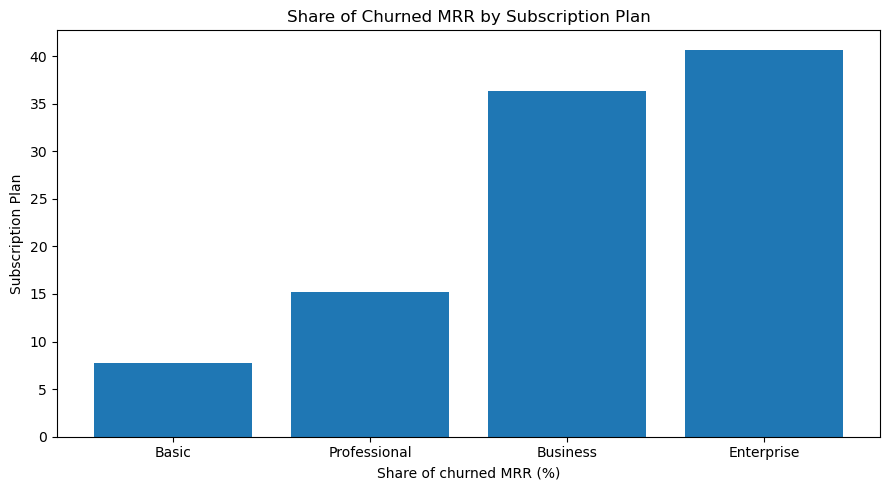

In [30]:
# Sort plans by their share of churned MRR
plot_data = churn_revenue.sort_values(
    "share_of_churned_mrr_pct"
)

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data.index,
    plot_data["share_of_churned_mrr_pct"]
)

plt.xlabel("Share of churned MRR (%)")
plt.ylabel("Subscription Plan")
plt.title("Share of Churned MRR by Subscription Plan")

plt.tight_layout()
plt.show()

Churn rate vs Revenue impact

In [31]:
churn_comparison= churn_revenue[
    [
        "churn_rate_pct",
        "share_of_churned_mrr_pct"
    ]
].copy()

churn_comparison.round(2)

,churn_rate_pct,share_of_churned_mrr_pct
plan,,
Enterprise,12.81,40.67
Business,12.26,36.31
Professional,11.84,15.25
Basic,14.85,7.77


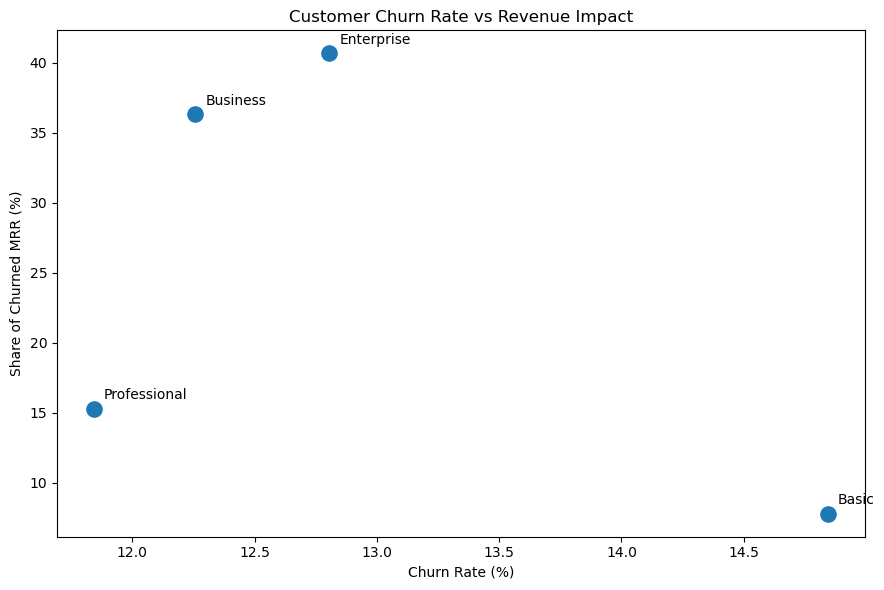

In [32]:
plt.figure(figsize=(9, 6))

plt.scatter(
    churn_comparison["churn_rate_pct"],
    churn_comparison["share_of_churned_mrr_pct"],
    s=120
)
for plan in churn_comparison.index:
    plt.annotate(
        plan,
        (
            churn_comparison.loc[plan, "churn_rate_pct"],
            churn_comparison.loc[plan, "share_of_churned_mrr_pct"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.xlabel("Churn Rate (%)")
plt.ylabel("Share of Churned MRR (%)")
plt.title("Customer Churn Rate vs Revenue Impact")

plt.tight_layout()
plt.show()

In [33]:
segment_churn = customers_clean.groupby("segment").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)

segment_churn["churn_rate_pct"] = segment_churn["churn_rate"] * 100

segment_churn = segment_churn.sort_values(
    "churn_rate_pct",
    ascending=False
)

segment_churn.round(2)

,total_customers,churned_customers,churn_rate,churn_rate_pct
segment,,,,
Mid-Market,1258,172.0,0.14,13.67
Enterprise,513,68.0,0.13,13.26
Startup,1236,163.0,0.13,13.19
Small Business,1993,253.0,0.13,12.69


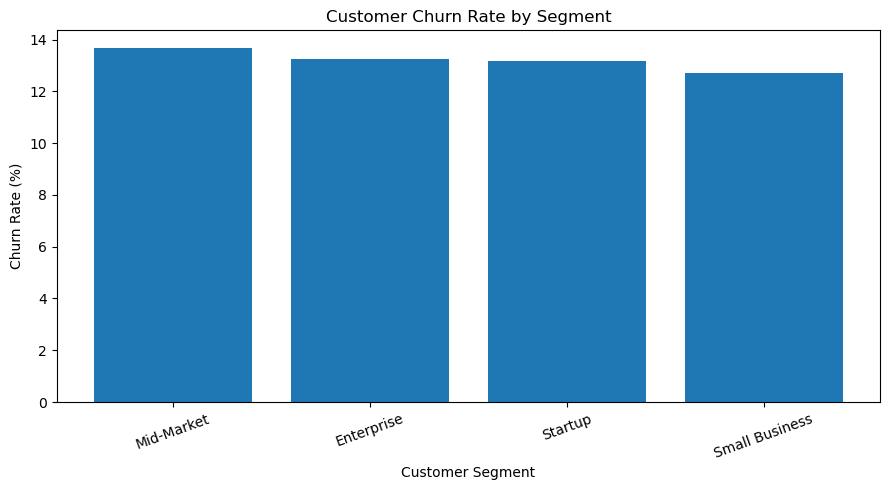

In [34]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_churn.index,
    segment_churn["churn_rate_pct"]
)

plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Segment")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Which industry has the highest churn?

In [35]:
industry_churn=customers_clean.groupby("industry").agg(
    total_customers=("customer_id", "count"),
    churned_customers = ("is_churned", "sum"),
    churn_rate = ("is_churned", "mean"),
)

industry_churn["churn_rate_pct"]=industry_churn["churn_rate"]*100

industry_churn=industry_churn.sort_values(
    "churn_rate_pct",
    ascending =False
)

industry_churn.round(2)

,total_customers,churned_customers,churn_rate,churn_rate_pct
industry,,,,
Finance,764,107.0,0.14,14.01
Technology,1207,164.0,0.14,13.59
Healthcare,770,104.0,0.14,13.51
Retail,610,81.0,0.13,13.28
Real Estate,357,47.0,0.13,13.17
Manufacturing,518,68.0,0.13,13.13
Education,430,52.0,0.12,12.09
Other,344,33.0,0.10,9.59


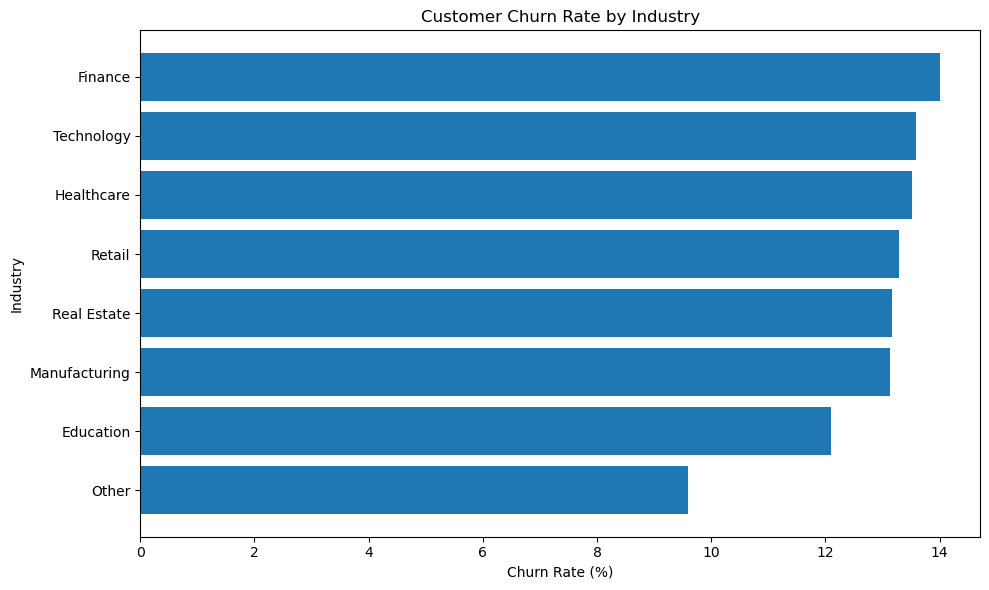

In [36]:
plt.figure(figsize=(10, 6))

plt.barh(
    industry_churn.index,
    industry_churn["churn_rate_pct"]
)

plt.xlabel("Churn Rate (%)")
plt.ylabel("Industry")
plt.title("Customer Churn Rate by Industry")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [37]:
usage_bins = [0, 20, 40, 60, 80, 100]
usage_labels = [
    "Very Low",
    "Low",
    "Medium",
    "High",
    "Very High"
]
customers_clean["usage_group"] = pd.cut(
    customers_clean["usage_score"],
    bins=usage_bins,
    labels=usage_labels,
    include_lowest=True
)

In [38]:
usage_churn=customers_clean.groupby("usage_group",observed=False).agg(
     total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)
usage_churn["churn_rate_pct"] = usage_churn["churn_rate"] * 100

usage_churn.round(2)

,total_customers,churned_customers,churn_rate,churn_rate_pct
usage_group,,,,
Very Low,55,17.0,0.31,30.91
Low,483,107.0,0.22,22.15
Medium,1539,283.0,0.18,18.39
High,1848,196.0,0.11,10.61
Very High,1075,53.0,0.05,4.93


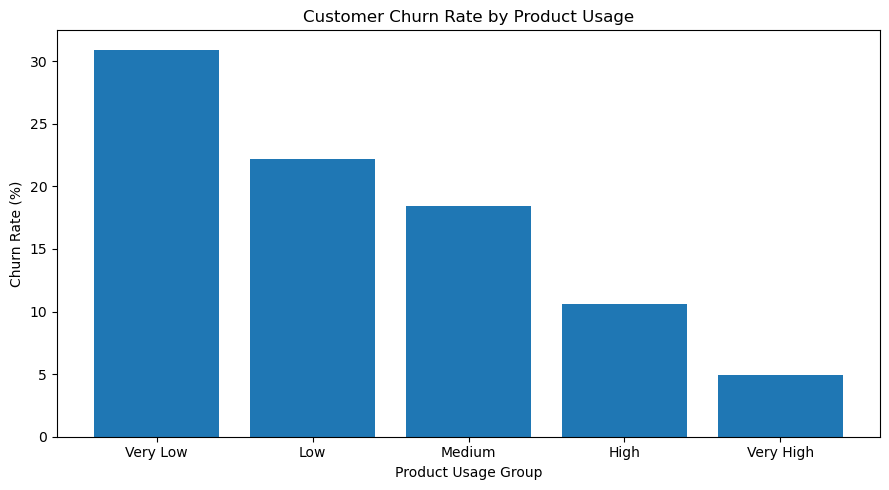

In [39]:
plt.figure(figsize=(9, 5))

plt.bar(
    usage_churn.index.astype(str),
    usage_churn["churn_rate_pct"]
)

plt.xlabel("Product Usage Group")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Product Usage")

plt.tight_layout()
plt.show()

In [40]:
customers_clean["support_tickets"].value_counts().sort_index()

support_tickets
0     699
1    1297
2    1341
3     913
4     466
5     195
6      67
7      17
8       4
9       1
Name: count, dtype: int64

In [41]:
support_churn = customers_clean.groupby("support_tickets").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)

support_churn["churn_rate_pct"] = support_churn["churn_rate"] * 100
support_churn=support_churn.sort_values(
    "churn_rate_pct",
    ascending =False
)

support_churn.round(2)

,total_customers,churned_customers,churn_rate,churn_rate_pct
support_tickets,,,,
7,17,4.0,0.24,23.53
3,913,137.0,0.15,15.01
0,699,96.0,0.14,13.73
4,466,63.0,0.14,13.52
2,1341,176.0,0.13,13.12
5,195,24.0,0.12,12.31
1,1297,149.0,0.11,11.49
6,67,7.0,0.10,10.45
8,4,0.0,0.00,0.00


In [42]:
customers_clean["support_group"] = customers_clean["support_tickets"].apply(
    lambda x: "4+" if x >= 4 else str(x)
)

In [43]:
support_group_churn = customers_clean.groupby("support_group").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)

support_group_churn["churn_rate_pct"] = (
    support_group_churn["churn_rate"] * 100
)

support_group_churn.round(2)

,total_customers,churned_customers,churn_rate,churn_rate_pct
support_group,,,,
0,699,96.0,0.14,13.73
1,1297,149.0,0.11,11.49
2,1341,176.0,0.13,13.12
3,913,137.0,0.15,15.01
4+,750,98.0,0.13,13.07


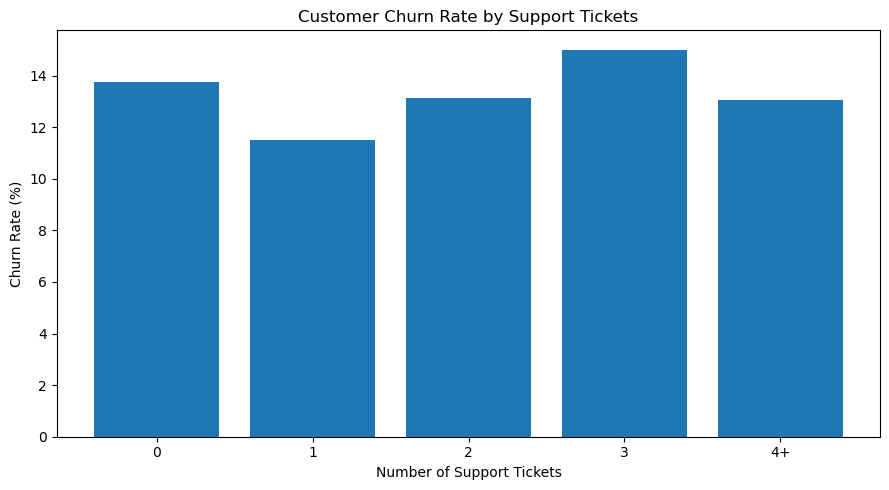

In [44]:
plt.figure(figsize=(9, 5))

plt.bar(
    support_group_churn.index,
    support_group_churn["churn_rate_pct"]
)

plt.xlabel("Number of Support Tickets")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Support Tickets")

plt.tight_layout()
plt.show()

Customer satisfaction (NPS)

In [45]:
customers_clean["nps_score"].describe()

count    5000.000000
mean       28.371600
std        38.396739
min      -100.000000
25%         2.000000
50%        29.000000
75%        56.000000
max       100.000000
Name: nps_score, dtype: float64

In [46]:
customers_clean["nps_category"] = customers_clean["nps_score"].apply(
    lambda x: "Negative" if x < 0
    else "Neutral" if x == 0
    else "Positive"
)

customers_clean["nps_category"].value_counts()

nps_category
Positive    3817
Negative    1123
Neutral       60
Name: count, dtype: int64

In [47]:
nps_churn = customers_clean.groupby("nps_category").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)

nps_churn["churn_rate_pct"] = nps_churn["churn_rate"] * 100

nps_churn.round(2)

,total_customers,churned_customers,churn_rate,churn_rate_pct
nps_category,,,,
Negative,1123,155.0,0.14,13.80
Neutral,60,10.0,0.17,16.67
Positive,3817,491.0,0.13,12.86


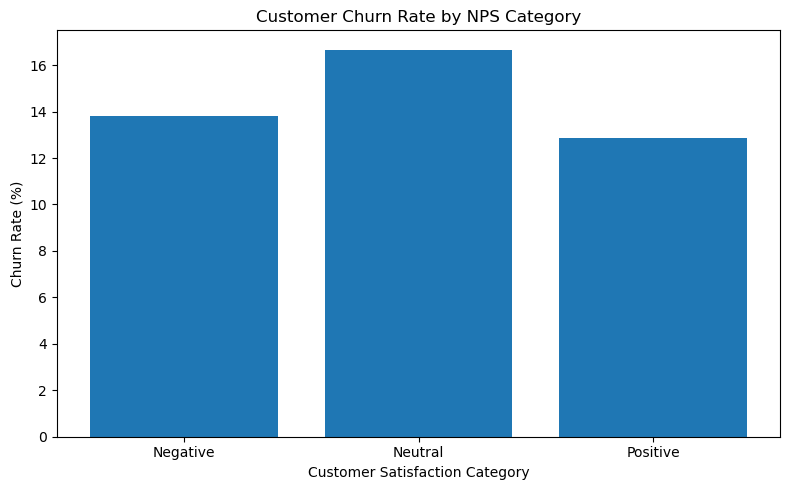

In [48]:
plt.figure(figsize=(8, 5))

plt.bar(
    nps_churn.index,
    nps_churn["churn_rate_pct"]
)

plt.xlabel("Customer Satisfaction Category")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by NPS Category")

plt.tight_layout()
plt.show()

In [49]:
customers_clean["contract_length"].value_counts().sort_index()

contract_length
1     1479
12    1969
24    1042
36     510
Name: count, dtype: int64

In [50]:
customers_clean["contract_group"] = customers_clean["contract_length"].apply(
    lambda x: "Short-term" if x == 1
    else "Medium-term" if x == 12
    else "Long-term"
)

In [51]:
contract_churn = customers_clean.groupby("contract_group").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)

contract_churn["churn_rate_pct"] = contract_churn["churn_rate"] * 100

contract_churn.round(2)

,total_customers,churned_customers,churn_rate,churn_rate_pct
contract_group,,,,
Long-term,1552,188.0,0.12,12.11
Medium-term,1969,263.0,0.13,13.36
Short-term,1479,205.0,0.14,13.86


In [52]:
plan_contract_churn = customers_clean.pivot_table(
    index="plan",
    columns="contract_group",
    values="is_churned",
    aggfunc="mean"
) * 100

plan_contract_churn.round(2)

contract_group,Long-term,Medium-term,Short-term
plan,,,
Basic,13.58,15.35,15.47
Business,12.57,12.38,11.76
Enterprise,10.34,13.99,14.02
Professional,10.68,11.49,13.55


In [53]:
plan_contract_counts = customers_clean.pivot_table(
    index="plan",
    columns="contract_group",
    values="customer_id",
    aggfunc="count"
)

plan_contract_counts

contract_group,Long-term,Medium-term,Short-term
plan,,,
Basic,545,710,530
Business,374,509,357
Enterprise,174,193,164
Professional,459,557,428


In [54]:
plan_contract_churned = customers_clean.pivot_table(
    index="plan",
    columns="contract_group",
    values="is_churned",
    aggfunc="sum"
)

plan_contract_churned

contract_group,Long-term,Medium-term,Short-term
plan,,,
Basic,74.0,109.0,82.0
Business,47.0,63.0,42.0
Enterprise,18.0,27.0,23.0
Professional,49.0,64.0,58.0


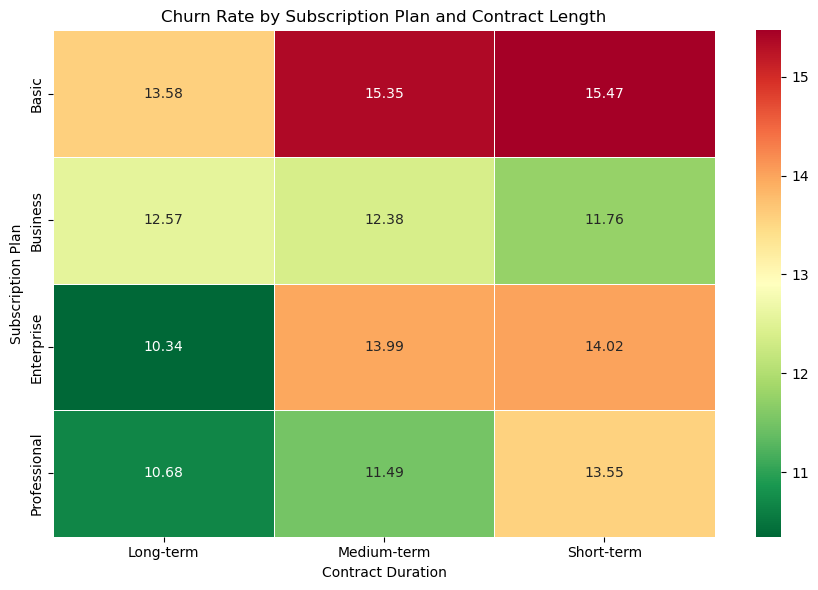

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

sns.heatmap(
    plan_contract_churn,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Churn Rate by Subscription Plan and Contract Length")
plt.xlabel("Contract Duration")
plt.ylabel("Subscription Plan")

plt.tight_layout()
plt.show()

Customer Lifetime Vlue -CLV

In [56]:
customers_clean["clv"].describe()

count     5000.000000
mean      7166.833910
std      10101.575347
min         44.540000
25%       1253.485000
50%       2907.190000
75%       8348.680000
max      61514.520000
Name: clv, dtype: float64

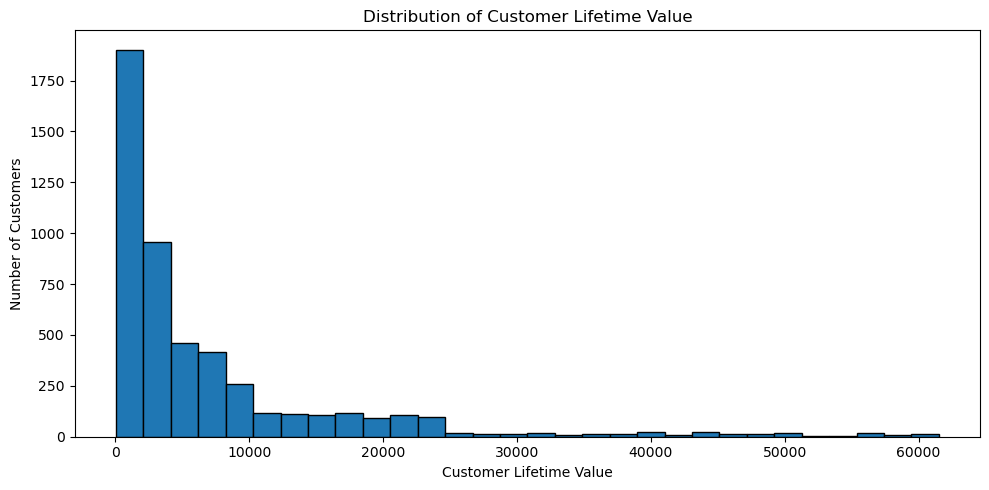

In [57]:
plt.figure(figsize=(10, 5))

plt.hist(
    customers_clean["clv"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Customer Lifetime Value")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Lifetime Value")

plt.tight_layout()
plt.show()

In [58]:
top_10_customers = customers_clean.sort_values(
    by="clv",
    ascending=False
).head(10)

top_10_customers[
    ["customer_id", "plan", "industry", "mrr", "clv", "is_churned"]
]

,customer_id,plan,industry,mrr,clv,is_churned
262,CUST_000263,Enterprise,Manufacturing,999,61514.52,0.0
2161,CUST_002162,Enterprise,Finance,999,61511.17,0.0
1259,CUST_001260,Enterprise,Retail,999,61425.16,0.0
453,CUST_000454,Enterprise,Finance,999,60614.89,0.0
4902,CUST_004903,Enterprise,Technology,999,60441.42,0.0
3658,CUST_003659,Enterprise,Education,999,60285.74,0.0
3030,CUST_003031,Enterprise,Technology,999,60214.89,0.0
3674,CUST_003675,Enterprise,Other,999,60189.62,0.0
2983,CUST_002984,Enterprise,Technology,999,60028.32,0.0
661,CUST_000662,Enterprise,Manufacturing,999,59868.27,0.0


Which subscription plan contributes the most historical customer revenue

In [59]:
clv_by_plan = customers_clean.groupby("plan").agg(
    total_customers=("customer_id", "count"),
    total_clv=("clv", "sum"),
    average_clv=("clv", "mean"),
    median_clv=("clv", "median")
)

clv_by_plan = clv_by_plan.sort_values(
    "total_clv",
    ascending=False
)

clv_by_plan.round(2)

,total_customers,total_clv,average_clv,median_clv
plan,,,,
Enterprise,531,13739327.16,25874.44,22156.75
Business,1240,13661159.10,11017.06,10063.65
Professional,1444,6021945.11,4170.32,3865.72
Basic,1785,2411738.18,1351.11,1182.70


Which subscription plan contributes the highest percentage of the company's total historical revenue?


In [60]:
total_revenue= clv_by_plan["total_clv"].sum()

clv_by_plan["revenue_contribution_pct"]=(
    clv_by_plan["total_clv"] / total_revenue) * 100

clv_by_plan.round(2)

,total_customers,total_clv,average_clv,median_clv,revenue_contribution_pct
plan,,,,,
Enterprise,531,13739327.16,25874.44,22156.75,38.34
Business,1240,13661159.10,11017.06,10063.65,38.12
Professional,1444,6021945.11,4170.32,3865.72,16.81
Basic,1785,2411738.18,1351.11,1182.70,6.73


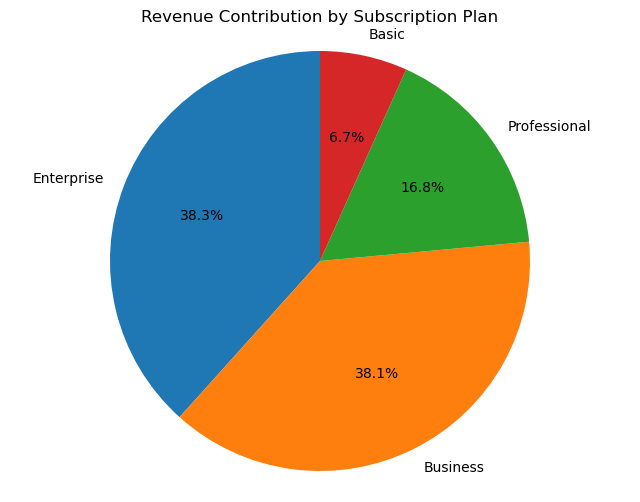

In [61]:
plt.figure(figsize=(8, 6))

plt.pie(
    clv_by_plan["revenue_contribution_pct"],
    labels=clv_by_plan.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Revenue Contribution by Subscription Plan")
plt.axis("equal")
plt.show()

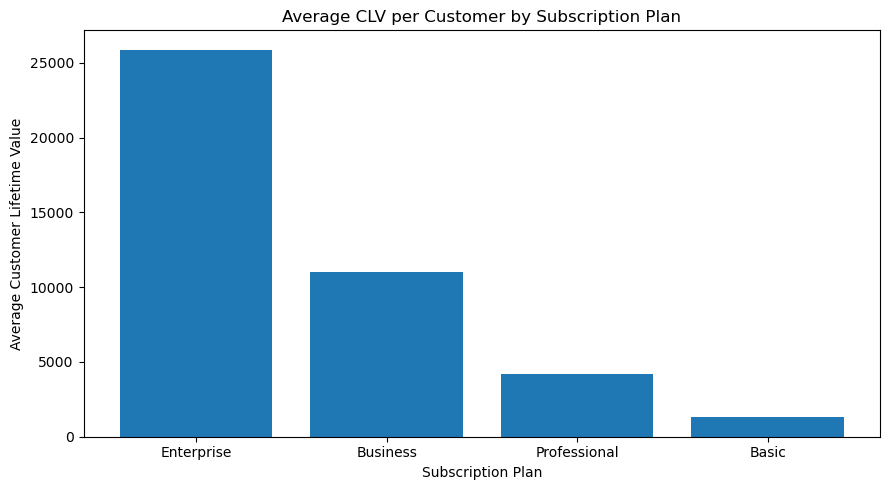

In [62]:
plt.figure(figsize=(9, 5))

plt.bar(
    clv_by_plan.index,
    clv_by_plan["average_clv"]
)

plt.xlabel("Subscription Plan")
plt.ylabel("Average Customer Lifetime Value")
plt.title("Average CLV per Customer by Subscription Plan")

plt.tight_layout()
plt.show()

Compare average CLV with median CLV

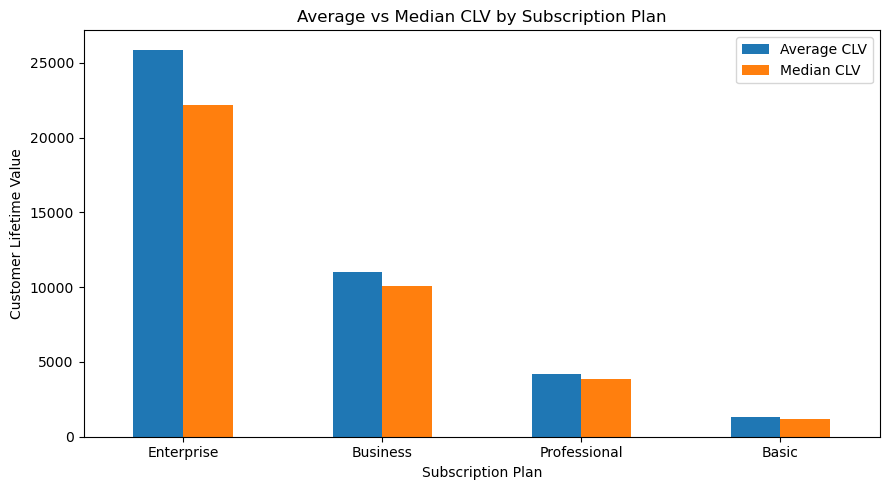

In [63]:
clv_by_plan[["average_clv", "median_clv"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.xlabel("Subscription Plan")
plt.ylabel("Customer Lifetime Value")
plt.title("Average vs Median CLV by Subscription Plan")
plt.xticks(rotation=0)
plt.legend(["Average CLV", "Median CLV"])
plt.tight_layout()
plt.show()

Highest-value customers

In [64]:
top_customers = customers_clean.sort_values(
    by="clv",
    ascending=False
)

top_customers[
    ["customer_id", "plan", "industry", "mrr", "clv", "is_churned"]
].head(10)

,customer_id,plan,industry,mrr,clv,is_churned
262,CUST_000263,Enterprise,Manufacturing,999,61514.52,0.0
2161,CUST_002162,Enterprise,Finance,999,61511.17,0.0
1259,CUST_001260,Enterprise,Retail,999,61425.16,0.0
453,CUST_000454,Enterprise,Finance,999,60614.89,0.0
4902,CUST_004903,Enterprise,Technology,999,60441.42,0.0
3658,CUST_003659,Enterprise,Education,999,60285.74,0.0
3030,CUST_003031,Enterprise,Technology,999,60214.89,0.0
3674,CUST_003675,Enterprise,Other,999,60189.62,0.0
2983,CUST_002984,Enterprise,Technology,999,60028.32,0.0
661,CUST_000662,Enterprise,Manufacturing,999,59868.27,0.0


Which subscription plan has the most high-value customers?


In [65]:
high_value_customers = customers_clean[
    customers_clean["clv"] >= 10000
]

high_value_summary = high_value_customers.groupby("plan").agg(
    high_value_customer_count=("customer_id", "count"),
    average_clv=("clv", "mean"),
    total_clv=("clv", "sum")
)

high_value_summary = high_value_summary.sort_values(
    by="high_value_customer_count",
    ascending=False
)

high_value_summary

,high_value_customer_count,average_clv,total_clv
plan,,,
Business,625,17010.160976,10631350.61
Enterprise,403,32338.873598,13032566.06


calculate the percentage of high-value customers

In [66]:
high_value_percentage = (
    high_value_customers.groupby("plan")["customer_id"].count()
    / customers_clean.groupby("plan")["customer_id"].count()
) * 100

high_value_percentage

plan
Basic                 NaN
Business        50.403226
Enterprise      75.894539
Professional          NaN
Name: customer_id, dtype: float64

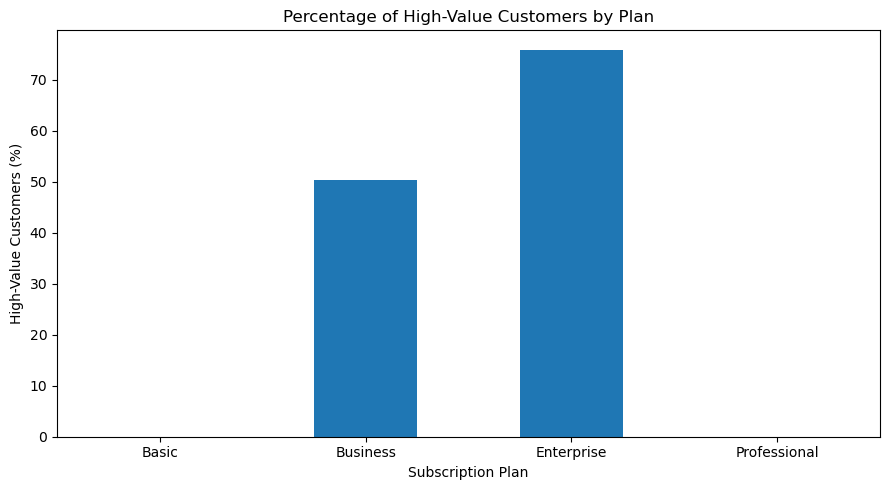

In [67]:
plt.figure(figsize=(9, 5))

high_value_percentage.plot(
    kind="bar"
)

plt.xlabel("Subscription Plan")
plt.ylabel("High-Value Customers (%)")
plt.title("Percentage of High-Value Customers by Plan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Are high-value customers churning?

In [68]:
high_value_churn = high_value_customers.groupby("plan").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)

high_value_churn["churn_rate_pct"] = (
    high_value_churn["churn_rate"] * 100
)

high_value_churn

,total_customers,churned_customers,churn_rate,churn_rate_pct
plan,,,,
Business,625,0.0,0.000000,0.000000
Enterprise,403,42.0,0.104218,10.421836


In [69]:
overall_churn_rate = customers_clean["is_churned"].mean() * 100

high_value_overall_churn = (
    high_value_customers["is_churned"].mean() * 100
)

print("Overall Customer Churn Rate:", round(overall_churn_rate, 2), "%")

print(
    "High-Value Customer Churn Rate:",
    round(high_value_overall_churn, 2), "%"
)

Overall Customer Churn Rate: 13.12 %
High-Value Customer Churn Rate: 4.09 %



Find the revenue associated with churned high-value customers


In [70]:
churned_high_value = high_value_customers[
    high_value_customers["is_churned"] == 1
]

churned_high_value_summary = churned_high_value.groupby("plan").agg(
    churned_customers=("customer_id", "count"),
    lost_historical_revenue=("clv", "sum"),
    average_clv=("clv", "mean")
)

churned_high_value_summary

,churned_customers,lost_historical_revenue,average_clv
plan,,,
Enterprise,42,671855.98,15996.570952


When these customers left


In [71]:
churned_high_value["churn_year"] = (
    churned_high_value["churn_date"].dt.year
)

churn_year_summary = churned_high_value.groupby("churn_year").agg(
    churned_customers=("customer_id", "count"),
    historical_revenue=("clv", "sum")
)

churn_year_summary

C:\Users\yadav\AppData\Local\Temp\ipykernel_21340\1034432447.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  churned_high_value["churn_year"] = (


,churned_customers,historical_revenue
churn_year,,
2021,4,53795.91
2022,10,177135.93
2023,16,257438.14
2024,12,183486.00


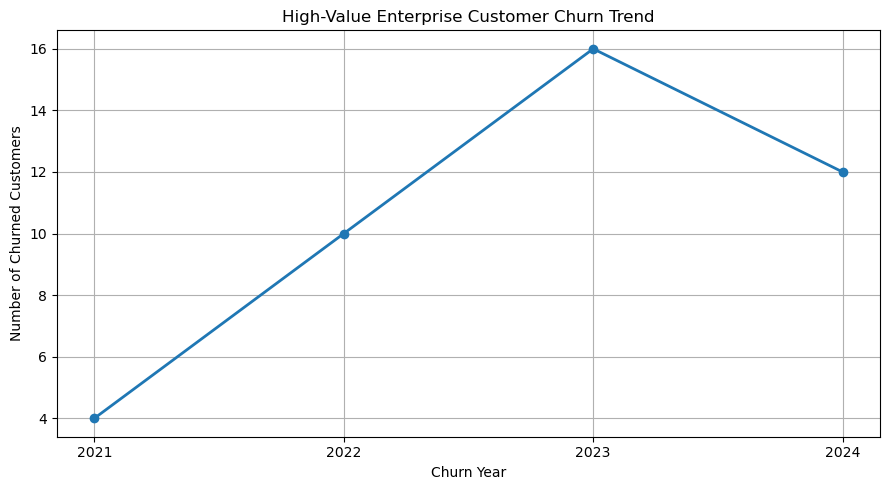

In [72]:
plt.figure(figsize=(9, 5))

plt.plot(
    churn_year_summary.index,
    churn_year_summary["churned_customers"],
    marker="o",
    linewidth=2
)

plt.xlabel("Churn Year")
plt.ylabel("Number of Churned Customers")
plt.title("High-Value Enterprise Customer Churn Trend")
plt.xticks(churn_year_summary.index)
plt.grid(True)
plt.tight_layout()
plt.show()

Does contract length affect high-value Enterprise customer churn?


In [73]:
churned_high_value.groupby("contract_group").agg(
    churned_customers=("customer_id", "count"),
    historical_revenue=("clv", "sum"),
    average_clv=("clv", "mean")
)

,churned_customers,historical_revenue,average_clv
contract_group,,,
Long-term,10,163575.69,16357.569000
Medium-term,19,287937.42,15154.601053
Short-term,13,220342.87,16949.451538


Actual churn rate by contract type

In [74]:
high_value_enterprise = high_value_customers[
    high_value_customers["plan"] == "Enterprise"
]

contract_churn_analysis = high_value_enterprise.groupby(
    "contract_group"
).agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean"),
    total_clv=("clv", "sum")
)

contract_churn_analysis["churn_rate_pct"] = (
    contract_churn_analysis["churn_rate"] * 100
)

contract_churn_analysis

,total_customers,churned_customers,churn_rate,total_clv,churn_rate_pct
contract_group,,,,,
Long-term,128,10.0,0.078125,4018977.00,7.812500
Medium-term,143,19.0,0.132867,4543597.99,13.286713
Short-term,132,13.0,0.098485,4469991.07,9.848485


In [75]:
enterprise_customers = customers_clean[
    customers_clean["plan"] == "Enterprise"
]

print(
    "Overall Enterprise churn:",
    round(enterprise_customers["is_churned"].mean() * 100, 2),
    "%"
)

print(
    "High-value Enterprise churn:",
    round(high_value_enterprise["is_churned"].mean() * 100, 2),
    "%"
)

Overall Enterprise churn: 12.81 %
High-value Enterprise churn: 10.42 %


Findings So far............

No.	Finding
1	Enterprise contributes 38.34% of total historical customer revenue.
2	Enterprise has the highest average CLV: 25,874.44.
3	75.89% of Enterprise customers meet our high-value threshold.
4	42 high-value Enterprise customers have churned.
5	Their combined historical revenue is 671,855.98.
6	2023 had the highest number of high-value Enterprise churn events: 16.
7	Medium-term contracts have the highest observed churn rate: 13.29%.
8	High-value Enterprise churn is 10.42%, compared with 12.81% for all Enterprise             customers.


Compare churned and active Enterprise customers to identify possible warning signs

In [76]:
enterprise_support = enterprise_customers.groupby("is_churned").agg(
    customer_count=("customer_id", "count"),
    average_tickets=("support_tickets", "mean"),
    median_tickets=("support_tickets", "median")
)

enterprise_support

,customer_count,average_tickets,median_tickets
is_churned,,,
0.0,463,2.131749,2.0
1.0,68,2.102941,2.0



Does customer support affect Enterprise churn?

In [77]:
enterprise_support= enterprise_customers.groupby("is_churned").agg(
    customer_count=("customer_id", "count"),
    average_tickets=("support_tickets", "mean"),
    median_tickets = ("support_tickets", "median")
)

enterprise_support
                     

,customer_count,average_tickets,median_tickets
is_churned,,,
0.0,463,2.131749,2.0
1.0,68,2.102941,2.0


Does customer satisfaction relate to Enterprise churn?

In [78]:
enterprise_nps = enterprise_customers.groupby("is_churned").agg(
    customer_count=("customer_id", "count"),
    average_nps=("nps_score", "mean"),
    median_nps=("nps_score", "median")
)

enterprise_nps

,customer_count,average_nps,median_nps
is_churned,,,
0.0,463,30.149028,29.0
1.0,68,24.691176,27.5


Compare with Contract Length

In [79]:
enterprise_contract = enterprise_customers.groupby("contract_group").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)

enterprise_contract["churn_rate_pct"] = (
    enterprise_contract["churn_rate"] * 100
)

enterprise_contract

,total_customers,churned_customers,churn_rate,churn_rate_pct
contract_group,,,,
Long-term,174,18.0,0.103448,10.344828
Medium-term,193,27.0,0.139896,13.989637
Short-term,164,23.0,0.140244,14.024390


Calculate the Enterprise churn rate by industry

In [80]:
enterprise_industry = enterprise_customers.groupby("industry").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("is_churned", "sum"),
    churn_rate=("is_churned", "mean")
)

enterprise_industry["churn_rate_pct"] = (
    enterprise_industry["churn_rate"] * 100
)

enterprise_industry.sort_values(
    "churn_rate_pct", ascending=False
)

,total_customers,churned_customers,churn_rate,churn_rate_pct
industry,,,,
Retail,61,11.0,0.180328,18.032787
Other,32,5.0,0.156250,15.625000
Technology,133,20.0,0.150376,15.037594
Manufacturing,48,7.0,0.145833,14.583333
Healthcare,89,11.0,0.123596,12.359551
Finance,87,8.0,0.091954,9.195402
Education,48,4.0,0.083333,8.333333
Real Estate,33,2.0,0.060606,6.060606


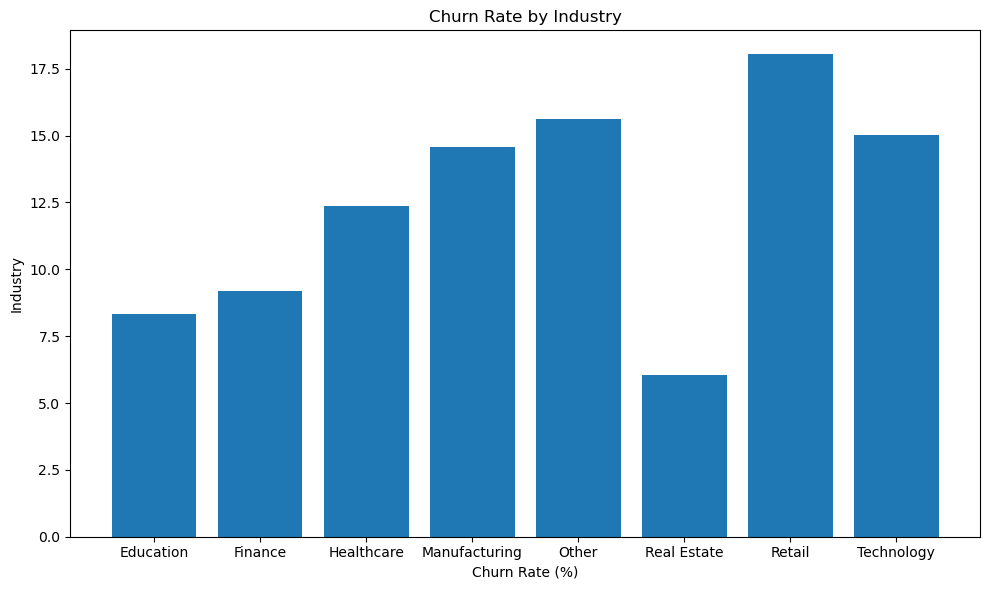

In [81]:
plt.figure(figsize=(10, 6))

plt.bar(
    enterprise_industry.index,
    enterprise_industry["churn_rate_pct"]
)

plt.title("Churn Rate by Industry")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()

Which Enterprise customers generate the most revenue?

In [82]:
enterprise_clv = enterprise_customers.groupby("is_churned").agg(
    customer_count=("customer_id", "count"),
    average_clv=("clv", "mean"),
    median_clv=("clv", "median"),
    total_clv=("clv", "sum")
)

enterprise_clv

,customer_count,average_clv,median_clv,total_clv
is_churned,,,,
0.0,463,27829.188898,26156.470,12884914.46
1.0,68,12564.892647,11911.625,854412.70


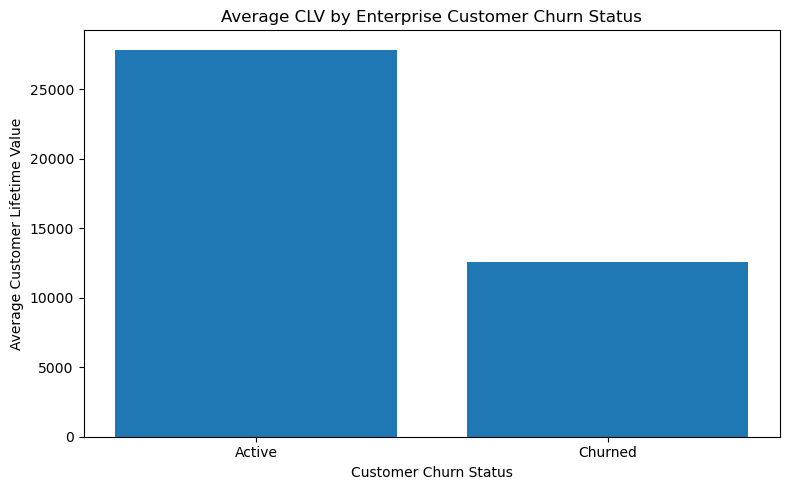

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    enterprise_clv.index.astype(str),
    enterprise_clv["average_clv"]
)

plt.title("Average CLV by Enterprise Customer Churn Status")
plt.xlabel("Customer Churn Status")
plt.ylabel("Average Customer Lifetime Value")

plt.xticks(
    [0, 1],
    ["Active", "Churned"]
)

plt.tight_layout()
plt.show()

In [84]:
enterprise_total_clv = enterprise_customers["clv"].sum()

enterprise_churned_clv = enterprise_customers.loc[
    enterprise_customers["is_churned"] == 1, "clv"
].sum()

enterprise_churn_summary = {
    "total_customers": len(enterprise_customers),
    "churned_customers": enterprise_customers["is_churned"].sum(),
    "churn_rate_pct": enterprise_customers["is_churned"].mean() * 100,
    "churned_clv_share_pct": (
        enterprise_churned_clv / enterprise_total_clv
    ) * 100
}

enterprise_churn_summary

{'total_customers': 531,
 'churned_customers': np.float64(68.0),
 'churn_rate_pct': np.float64(12.8060263653484),
 'churned_clv_share_pct': np.float64(6.218737570261046)}

In [85]:
import pandas as pd
import numpy as np

In [86]:
transactions = pd.read_csv("../Datasets/financial_transactions.csv")

print("Dataset shape:", transactions.shape)

transactions.head()

Dataset shape: (135218, 10)


,transaction_id,customer_id,transaction_date,amount,transaction_type,status,payment_method,year_month,cohort_month,transaction_month
0,CUST_000001_TXN_0001,CUST_000001,2023-01-31,52.78,New,Completed,Credit Card,2023-01,2023-01,2023-01
1,CUST_000001_TXN_0002,CUST_000001,2023-02-28,52.87,Subscription,Completed,Credit Card,2023-02,2023-01,2023-02
2,CUST_000001_TXN_0003,CUST_000001,2023-03-28,52.84,Subscription,Completed,Credit Card,2023-03,2023-01,2023-03
3,CUST_000001_TXN_0004,CUST_000001,2023-04-28,53.22,Subscription,Completed,Credit Card,2023-04,2023-01,2023-04
4,CUST_000001_TXN_0005,CUST_000001,2023-05-28,51.86,Subscription,Completed,Wire Transfer,2023-05,2023-01,2023-05


In [87]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135218 entries, 0 to 135217
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   transaction_id     135218 non-null  object 
 1   customer_id        135218 non-null  object 
 2   transaction_date   135218 non-null  object 
 3   amount             135218 non-null  float64
 4   transaction_type   135218 non-null  object 
 5   status             135218 non-null  object 
 6   payment_method     135218 non-null  object 
 7   year_month         135218 non-null  object 
 8   cohort_month       135218 non-null  object 
 9   transaction_month  135218 non-null  object 
dtypes: float64(1), object(9)
memory usage: 10.3+ MB


In [88]:
transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

In [89]:
transactions["transaction_date"].dtype

dtype('<M8[ns]')

In [90]:
transactions["transaction_date"].head()

0   2023-01-31
1   2023-02-28
2   2023-03-28
3   2023-04-28
4   2023-05-28
Name: transaction_date, dtype: datetime64[ns]

In [91]:
transactions["transaction_type"].value_counts()

transaction_type
Subscription    130218
New               5000
Name: count, dtype: int64

In [92]:
transactions["status"].value_counts()

status
Completed    135218
Name: count, dtype: int64

In [93]:
transactions["payment_method"].value_counts()

payment_method
Credit Card      80766
ACH              27318
Wire Transfer    20430
PayPal            6704
Name: count, dtype: int64

In [94]:
transactions["transaction_id"].nunique()

135218

In [95]:
transactions["transaction_id"].duplicated().sum()

np.int64(0)

In [96]:
transactions.duplicated().sum()

np.int64(0)

In [97]:
transactions.describe

<bound method NDFrame.describe of               transaction_id  customer_id transaction_date  amount  \
0       CUST_000001_TXN_0001  CUST_000001       2023-01-31   52.78   
1       CUST_000001_TXN_0002  CUST_000001       2023-02-28   52.87   
2       CUST_000001_TXN_0003  CUST_000001       2023-03-28   52.84   
3       CUST_000001_TXN_0004  CUST_000001       2023-04-28   53.22   
4       CUST_000001_TXN_0005  CUST_000001       2023-05-28   51.86   
...                      ...          ...              ...     ...   
135213  CUST_005000_TXN_0003  CUST_005000       2024-08-11  141.28   
135214  CUST_005000_TXN_0004  CUST_005000       2024-09-11  139.38   
135215  CUST_005000_TXN_0005  CUST_005000       2024-10-11  157.33   
135216  CUST_005000_TXN_0006  CUST_005000       2024-11-11  224.64   
135217  CUST_005000_TXN_0007  CUST_005000       2024-12-11  162.46   

       transaction_type     status payment_method year_month cohort_month  \
0                   New  Completed    Credit Car

In [98]:
transactions["amount"].describe()

count    135218.000000
mean        265.010350
std         288.410528
min          44.100000
25%          51.340000
50%         149.375000
75%         392.617500
max        1629.700000
Name: amount, dtype: float64

In [99]:
(transactions["amount"] <= 0).sum()

np.int64(0)

In [100]:
transactions["amount"].dtype

dtype('float64')

In [101]:
transactions["customer_id"].nunique()

5000

In [102]:
transactions["customer_id"].isnull().sum()

np.int64(0)

Find the latest transaction date

In [103]:
transactions["transaction_date"].max()

Timestamp('2024-12-30 00:00:00')

In [104]:
reference_date = transactions["transaction_date"].max()

print("Reference Date:", reference_date)

Reference Date: 2024-12-30 00:00:00


Find each customer's last transaction date

In [105]:
last_transaction = transactions.groupby("customer_id")["transaction_date"].max()

last_transaction.head()

customer_id
CUST_000001   2024-12-28
CUST_000002   2024-12-29
CUST_000003   2024-03-10
CUST_000004   2024-12-18
CUST_000005   2024-12-04
Name: transaction_date, dtype: datetime64[ns]

In [106]:
recency = (reference_date - last_transaction).dt.days

recency.head()

customer_id
CUST_000001      2
CUST_000002      1
CUST_000003    295
CUST_000004     12
CUST_000005     26
Name: transaction_date, dtype: int64

In [107]:
recency.describe()

count    5000.000000
mean      107.697600
std       286.277569
min         0.000000
25%         8.000000
50%        17.000000
75%        26.000000
max      1716.000000
Name: transaction_date, dtype: float64

How many transactions each customer has made.

In [108]:
frequency = transactions.groupby("customer_id")["transaction_id"].count()

frequency.head()

customer_id
CUST_000001    24
CUST_000002    13
CUST_000003    23
CUST_000004    18
CUST_000005    23
Name: transaction_id, dtype: int64

In [109]:
frequency.describe()

count    5000.000000
mean       27.043600
std        17.226545
min         1.000000
25%        12.000000
50%        24.000000
75%        42.000000
max        60.000000
Name: transaction_id, dtype: float64

Calculate Monetary (M)

In [110]:
monetary = transactions.groupby("customer_id")["amount"].sum()

monetary.head()

customer_id
CUST_000001    1194.63
CUST_000002     676.89
CUST_000003    3470.20
CUST_000004    7107.69
CUST_000005    9839.84
Name: amount, dtype: float64

In [111]:
monetary.describe()

count     5000.000000
mean      7166.833910
std      10101.575347
min         44.540000
25%       1253.485000
50%       2907.190000
75%       8348.680000
max      61514.520000
Name: amount, dtype: float64

In [112]:
rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

rfm.head()

,Recency,Frequency,Monetary
customer_id,,,
CUST_000001,2,24,1194.63
CUST_000002,1,13,676.89
CUST_000003,295,23,3470.20
CUST_000004,12,18,7107.69
CUST_000005,26,23,9839.84


In [113]:
rfm.shape

(5000, 3)

In [114]:
rfm.describe()

,Recency,Frequency,Monetary
count,5000.000000,5000.000000,5000.000000
mean,107.697600,27.043600,7166.833910
std,286.277569,17.226545,10101.575347
min,0.000000,1.000000,44.540000
25%,8.000000,12.000000,1253.485000
50%,17.000000,24.000000,2907.190000
75%,26.000000,42.000000,8348.680000
max,1716.000000,60.000000,61514.520000


Assign RFM scores

In [115]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=5,
    labels=[5, 4, 3, 2, 1]
)

In [116]:
rfm[["Recency", "R_Score"]].head(10)

,Recency,R_Score
customer_id,,
CUST_000001,2,5
CUST_000002,1,5
CUST_000003,295,1
CUST_000004,12,4
CUST_000005,26,2
CUST_000006,2,5
CUST_000007,10,4
CUST_000008,20,3
CUST_000009,4,5


In [117]:
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"],
    q=5,
    labels=[1, 2, 3, 4, 5]
)

In [118]:
rfm[["Frequency", "F_Score"]].head(10)

,Frequency,F_Score
customer_id,,
CUST_000001,24,3
CUST_000002,13,2
CUST_000003,23,3
CUST_000004,18,2
CUST_000005,23,3
CUST_000006,25,3
CUST_000007,4,1
CUST_000008,26,3
CUST_000009,7,1


In [119]:
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    q=5,
    labels=[1, 2, 3, 4, 5]
)

In [120]:
rfm[["Monetary", "M_Score"]].head(10)

,Monetary,M_Score
customer_id,,
CUST_000001,1194.63,2
CUST_000002,676.89,1
CUST_000003,3470.20,3
CUST_000004,7107.69,4
CUST_000005,9839.84,4
CUST_000006,1249.22,2
CUST_000007,625.35,1
CUST_000008,10379.77,4
CUST_000009,1103.88,2


In [121]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

In [122]:
rfm[[
    "Recency", "Frequency", "Monetary",
    "R_Score", "F_Score", "M_Score", "RFM_Score"
]].head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
customer_id,,,,,,,
CUST_000001,2,24,1194.63,5,3,2,532
CUST_000002,1,13,676.89,5,2,1,521
CUST_000003,295,23,3470.20,1,3,3,133
CUST_000004,12,18,7107.69,4,2,4,424
CUST_000005,26,23,9839.84,2,3,4,234
CUST_000006,2,25,1249.22,5,3,2,532
CUST_000007,10,4,625.35,4,1,1,411
CUST_000008,20,26,10379.77,3,3,4,334
CUST_000009,4,7,1103.88,5,1,2,512


In [123]:
rfm[["R_Score", "F_Score", "M_Score", "RFM_Score"]].head(10)

,R_Score,F_Score,M_Score,RFM_Score
customer_id,,,,
CUST_000001,5,3,2,532
CUST_000002,5,2,1,521
CUST_000003,1,3,3,133
CUST_000004,4,2,4,424
CUST_000005,2,3,4,234
CUST_000006,5,3,2,532
CUST_000007,4,1,1,411
CUST_000008,3,3,4,334
CUST_000009,5,1,2,512


In [124]:
rfm["RFM_Score"].value_counts().head(10)

RFM_Score
111    137
121    137
511    119
311    113
211    112
411    110
542     89
445     88
253     85
555     84
Name: count, dtype: int64

In [125]:
def segment_customer(row):

    if row["RFM_Score"] == "555":
        return "Champions"

    elif row["F_Score"] >= 4 and row["R_Score"] >= 3:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Potential Loyalists"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Hibernating"

    else:
        return "Others"

In [126]:
rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

In [127]:
rfm["Customer_Segment"].value_counts()

Customer_Segment
Loyal Customers        1260
Hibernating            1012
At Risk                 984
Others                  953
Potential Loyalists     707
Champions                84
Name: count, dtype: int64

Calculate segment percentages automatically

In [128]:
segment_summary = rfm["Customer_Segment"].value_counts().reset_index()

segment_summary.columns = ["Customer_Segment", "Customer_Count"]

segment_summary["Percentage"] = (
    segment_summary["Customer_Count"] / len(rfm) * 100
).round(2)

segment_summary

,Customer_Segment,Customer_Count,Percentage
0,Loyal Customers,1260,25.20
1,Hibernating,1012,20.24
2,At Risk,984,19.68
3,Others,953,19.06
4,Potential Loyalists,707,14.14
5,Champions,84,1.68


In [129]:
segment_analysis = rfm.groupby("Customer_Segment").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

segment_analysis

,Recency,Frequency,Monetary
Customer_Segment,,,
At Risk,94.73,37.64,10220.38
Champions,3.06,52.46,26601.46
Hibernating,411.10,10.76,2927.91
Loyal Customers,10.18,45.35,10874.47
Others,12.36,19.85,5352.41
Potential Loyalists,6.20,9.65,2513.54


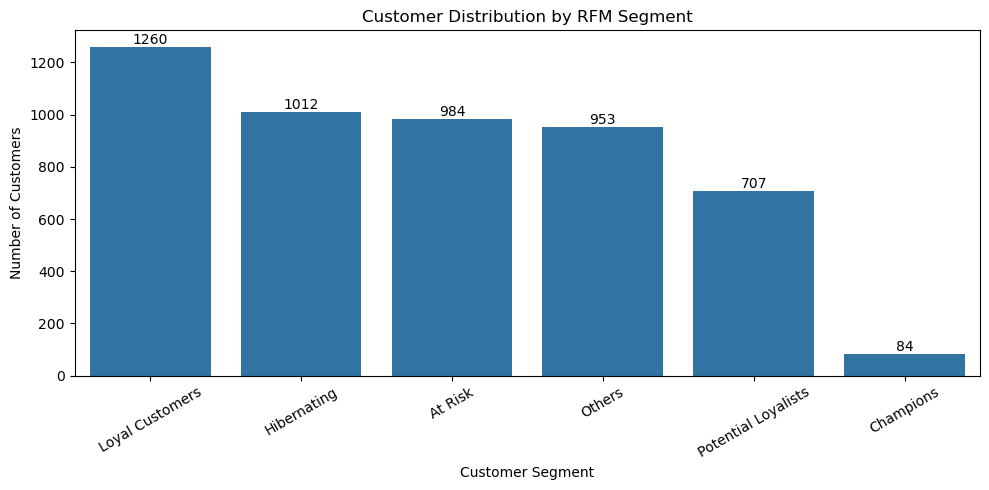

In [130]:
plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=rfm,
    x="Customer_Segment",
    order=rfm["Customer_Segment"].value_counts().index
)

# Add customer counts above each bar
for bar in ax.patches:
    ax.annotate(
        int(bar.get_height()),
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

RFM customer segments

In [131]:
customers[["customer_id", "is_churned"]].head()

,customer_id,is_churned
0,CUST_000001,0.0
1,CUST_000002,0.0
2,CUST_000003,1.0
3,CUST_000004,0.0
4,CUST_000005,0.0


In [132]:
rfm_churn = rfm.reset_index().merge(
    customers[["customer_id", "is_churned"]],
    on="customer_id",
    how="left"
)

In [133]:
print("Shape:", rfm_churn.shape)

rfm_churn[[
    "customer_id",
    "Customer_Segment",
    "is_churned"
]].head(10)

Shape: (5000, 10)


,customer_id,Customer_Segment,is_churned
0,CUST_000001,Others,0.0
1,CUST_000002,Potential Loyalists,0.0
2,CUST_000003,At Risk,1.0
3,CUST_000004,Potential Loyalists,0.0
4,CUST_000005,At Risk,0.0
5,CUST_000006,Others,0.0
6,CUST_000007,Potential Loyalists,0.0
7,CUST_000008,Others,0.0
8,CUST_000009,Potential Loyalists,0.0
9,CUST_000010,At Risk,0.0


In [134]:
churn_analysis = rfm_churn.groupby("Customer_Segment").agg({
    "is_churned": ["count", "sum", "mean"]
}).round(3)

churn_analysis

is_churned              
                         count    sum   mean
Customer_Segment                            
At Risk                    984  125.0  0.127
Champions                   84    0.0  0.000
Hibernating               1012  530.0  0.524
Loyal Customers           1260    0.0  0.000
Others                     953    1.0  0.001
Potential Loyalists        707    0.0  0.000

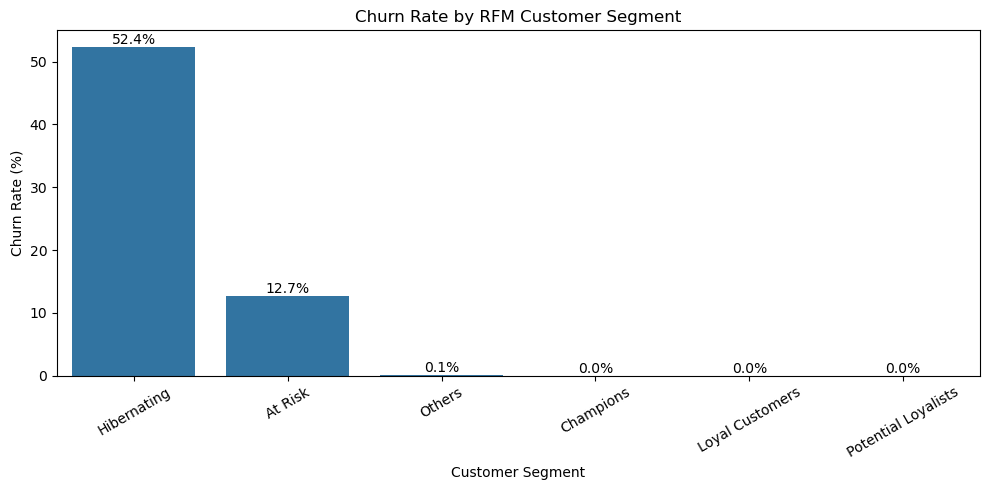

In [135]:
churn_rate = (
    rfm_churn.groupby("Customer_Segment")["is_churned"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Churn Rate by RFM Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Calculate the overall churn rate

In [136]:
overall_churn_rate = rfm_churn["is_churned"].mean() * 100

print("Overall Churn Rate:", round(overall_churn_rate, 2), "%")

Overall Churn Rate: 13.12 %


In [137]:
segment_comparison = (
    rfm_churn.groupby("Customer_Segment")
    .agg(
        Total_Customers=("is_churned", "count"),
        Churned_Customers=("is_churned", "sum"),
        Churn_Rate=("is_churned", "mean")
    )
)

segment_comparison["Churn_Rate"] *= 100

segment_comparison["Difference_from_Overall"] = (
    segment_comparison["Churn_Rate"] - overall_churn_rate
)

segment_comparison.round(2)

,Total_Customers,Churned_Customers,Churn_Rate,Difference_from_Overall
Customer_Segment,,,,
At Risk,984,125.0,12.70,-0.42
Champions,84,0.0,0.00,-13.12
Hibernating,1012,530.0,52.37,39.25
Loyal Customers,1260,0.0,0.00,-13.12
Others,953,1.0,0.10,-13.02
Potential Loyalists,707,0.0,0.00,-13.12


Calculate how much of total churn comes from Hibernating customers

In [138]:
total_churned = rfm_churn["is_churned"].sum()

hibernating_churned = rfm_churn.loc[
    rfm_churn["Customer_Segment"] == "Hibernating",
    "is_churned"
].sum()

hibernating_contribution = (
    hibernating_churned / total_churned
) * 100

print("Total churned customers:", int(total_churned))
print("Hibernating churned customers:", int(hibernating_churned))
print(
    "Hibernating contribution to total churn:",
    round(hibernating_contribution, 2),
    "%"
)

Total churned customers: 656
Hibernating churned customers: 530
Hibernating contribution to total churn: 80.79 %


In [139]:
revenue_analysis = rfm_churn.groupby("Customer_Segment").agg(
    Total_Customers=("customer_id", "count"),
    Total_Revenue=("Monetary", "sum"),
    Average_Revenue=("Monetary", "mean")
)

revenue_analysis["Revenue_Percentage"] = (
    revenue_analysis["Total_Revenue"] /
    revenue_analysis["Total_Revenue"].sum()
) * 100

revenue_analysis.round(2)

,Total_Customers,Total_Revenue,Average_Revenue,Revenue_Percentage
Customer_Segment,,,,
At Risk,984,10056853.68,10220.38,28.06
Champions,84,2234523.06,26601.46,6.24
Hibernating,1012,2963045.44,2927.91,8.27
Loyal Customers,1260,13701827.27,10874.47,38.24
Others,953,5100847.28,5352.41,14.23
Potential Loyalists,707,1777072.82,2513.54,4.96


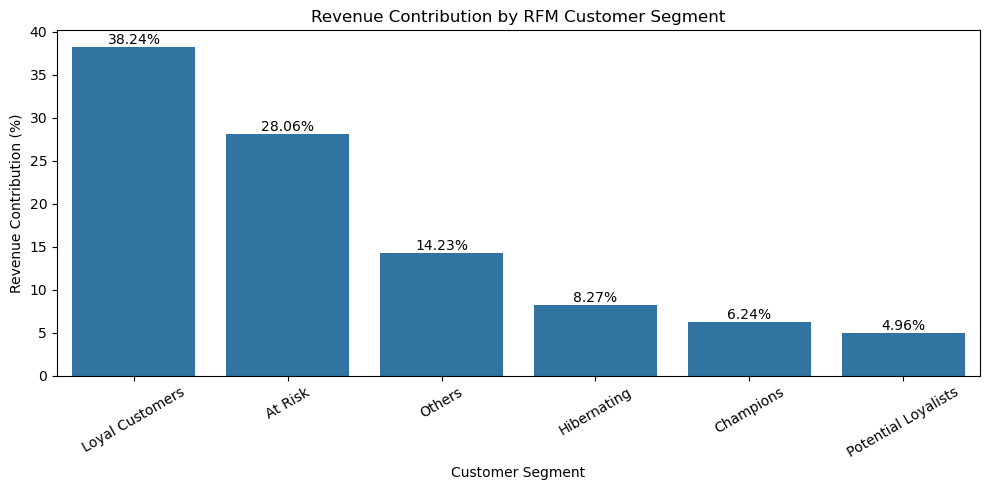

In [140]:
revenue_percentage = (
    revenue_analysis["Revenue_Percentage"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=revenue_percentage.index,
    y=revenue_percentage.values
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Revenue Contribution by RFM Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [141]:
final_rfm_summary = rfm_churn.groupby("Customer_Segment").agg(
    Customer_Count=("customer_id", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Churn_Rate=("is_churned", "mean"),
    Total_Revenue=("Monetary", "sum")
)

final_rfm_summary["Churn_Rate"] *= 100

final_rfm_summary["Revenue_Contribution"] = (
    final_rfm_summary["Total_Revenue"] /
    final_rfm_summary["Total_Revenue"].sum()
) * 100

final_rfm_summary = final_rfm_summary.round(2)

final_rfm_summary

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Churn_Rate,Total_Revenue,Revenue_Contribution
Customer_Segment,,,,,,,
At Risk,984,94.73,37.64,10220.38,12.70,10056853.68,28.06
Champions,84,3.06,52.46,26601.46,0.00,2234523.06,6.24
Hibernating,1012,411.10,10.76,2927.91,52.37,2963045.44,8.27
Loyal Customers,1260,10.18,45.35,10874.47,0.00,13701827.27,38.24
Others,953,12.36,19.85,5352.41,0.10,5100847.28,14.23
Potential Loyalists,707,6.20,9.65,2513.54,0.00,1777072.82,4.96


In [142]:
rfm["R_Score"] = rfm["R_Score"].astype(int)
rfm["F_Score"] = rfm["F_Score"].astype(int)
rfm["M_Score"] = rfm["M_Score"].astype(int)

In [143]:
rfm.groupby("Customer_Segment")[[
    "R_Score",
    "F_Score",
    "M_Score"
]].mean().round(2)

,R_Score,F_Score,M_Score
Customer_Segment,,,
At Risk,1.65,3.92,3.57
Champions,5.00,5.00,5.00
Hibernating,1.39,1.51,2.20
Loyal Customers,3.99,4.47,3.75
Others,3.66,2.44,2.79
Potential Loyalists,4.53,1.43,2.05


In [144]:
rfm_churn[
    rfm_churn["Customer_Segment"] == "At Risk"
]["is_churned"].value_counts()

is_churned
0.0    859
1.0    125
Name: count, dtype: int64

In [145]:
rfm_churn[
    rfm_churn["Customer_Segment"] == "Hibernating"
]["is_churned"].value_counts()

is_churned
1.0    530
0.0    482
Name: count, dtype: int64

Compare all segments in one table

In [146]:
churn_breakdown = pd.crosstab(
    rfm_churn["Customer_Segment"],
    rfm_churn["is_churned"],
    normalize="index"
) * 100

churn_breakdown = churn_breakdown.rename(
    columns={0.0: "Not_Churned_%", 1.0: "Churned_%"}
)

churn_breakdown.round(2)

is_churned,Not_Churned_%,Churned_%
Customer_Segment,,
At Risk,87.30,12.70
Champions,100.00,0.00
Hibernating,47.63,52.37
Loyal Customers,100.00,0.00
Others,99.90,0.10
Potential Loyalists,100.00,0.00


In [147]:
churned_customers = customers[
    customers["is_churned"] == 1
][[
    "customer_id",
    "signup_date",
    "churn_date",
    "last_transaction_date",
    "is_churned"
]]

churned_customers.head()

,customer_id,signup_date,churn_date,last_transaction_date,is_churned
2,CUST_000003,2022-05-10,2024-03-22,2024-03-10,1.0
12,CUST_000013,2020-11-26,2021-03-31,2021-03-26,1.0
22,CUST_000023,2022-02-08,2023-11-10,2023-11-08,1.0
24,CUST_000025,2024-02-24,2024-12-01,2024-11-24,1.0
28,CUST_000029,2023-04-30,2024-04-10,2024-03-29,1.0


Calculate the gap for every churned customer

In [148]:
churned_customers["Churn_Gap_Days"] = (
    pd.to_datetime(churned_customers["churn_date"]) -
    pd.to_datetime(churned_customers["last_transaction_date"])
).dt.days

churned_customers["Churn_Gap_Days"].describe()

count    656.000000
mean      14.734756
std        8.893934
min        0.000000
25%        7.000000
50%       15.000000
75%       22.000000
max       30.000000
Name: Churn_Gap_Days, dtype: float64

In [149]:
(churned_customers["Churn_Gap_Days"] < 0).sum()

np.int64(0)

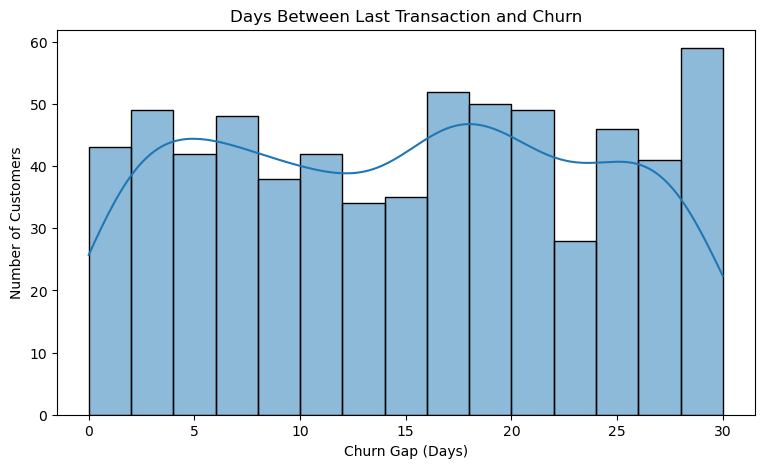

In [150]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=churned_customers,
    x="Churn_Gap_Days",
    bins=15,
    kde=True
)

plt.title("Days Between Last Transaction and Churn")
plt.xlabel("Churn Gap (Days)")
plt.ylabel("Number of Customers")

plt.show()

In [151]:
rfm_churn.to_csv("rfm_customer_analysis.csv", index=False)

In [152]:
total_customers = rfm_churn["customer_id"].nunique()

total_churned = rfm_churn["is_churned"].sum()

churn_rate = (
    total_churned / total_customers
) * 100

total_revenue = rfm_churn["Monetary"].sum()

average_revenue = rfm_churn["Monetary"].mean()

print("BUSINESS PERFORMANCE KPIs")
print("--------------------------")
print("Total Customers:", total_customers)
print("Churned Customers:", total_churned)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Total Historical Revenue:", round(total_revenue, 2))
print("Average Revenue per Customer:", round(average_revenue, 2))

BUSINESS PERFORMANCE KPIs
--------------------------
Total Customers: 5000
Churned Customers: 656.0
Churn Rate: 13.12 %
Total Historical Revenue: 35834169.55
Average Revenue per Customer: 7166.83


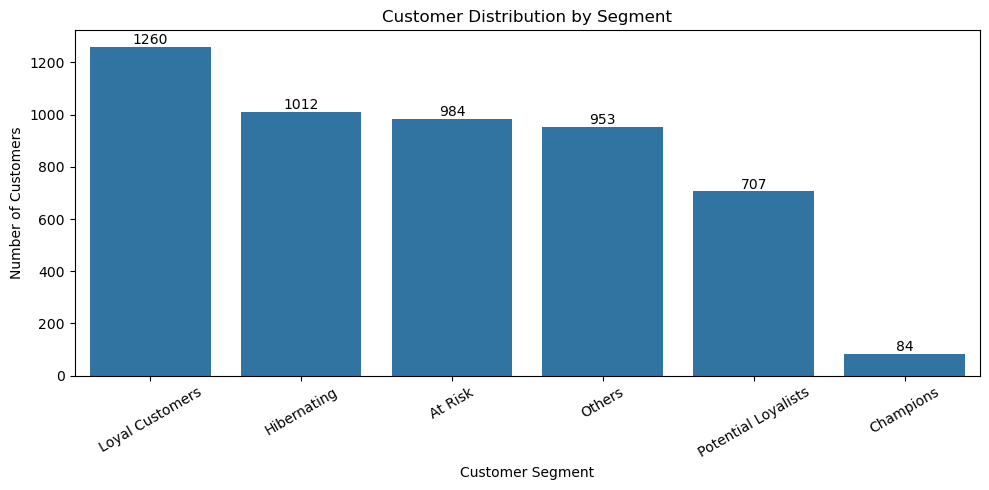

In [153]:
import matplotlib.pyplot as plt
import seaborn as sns

segment_counts = rfm_churn["Customer_Segment"].value_counts()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

for i, value in enumerate(segment_counts.values):
    plt.text(i, value + 10, str(value), ha="center")

plt.tight_layout()
plt.show()

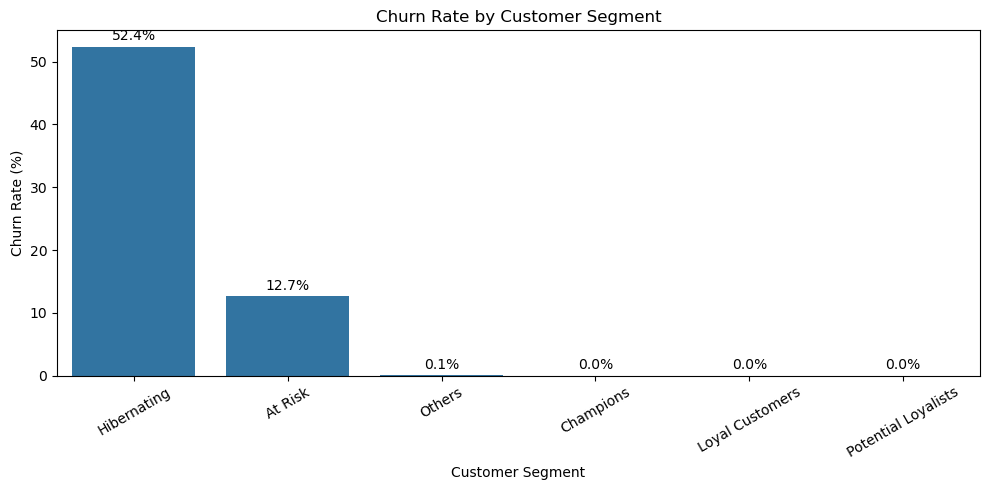

In [154]:
churn_by_segment = (
    rfm_churn.groupby("Customer_Segment")["is_churned"]
    .mean() * 100
)

churn_by_segment = churn_by_segment.sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=churn_by_segment.index,
    y=churn_by_segment.values
)

plt.title("Churn Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)

for i, value in enumerate(churn_by_segment.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

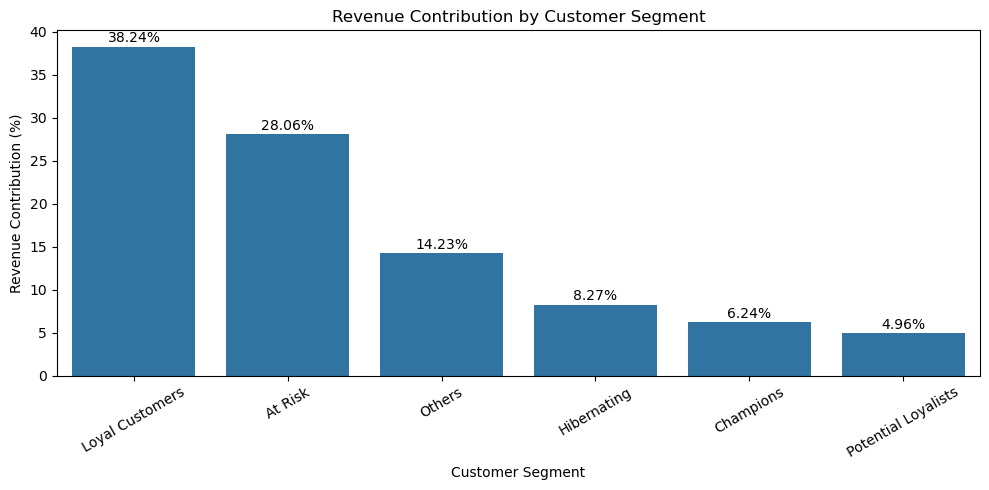

In [155]:
revenue_by_segment = (
    rfm_churn.groupby("Customer_Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

revenue_percentage = (
    revenue_by_segment / revenue_by_segment.sum()
) * 100

plt.figure(figsize=(10, 5))

sns.barplot(
    x=revenue_percentage.index,
    y=revenue_percentage.values
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")
plt.xticks(rotation=30)

for i, value in enumerate(revenue_percentage.values):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

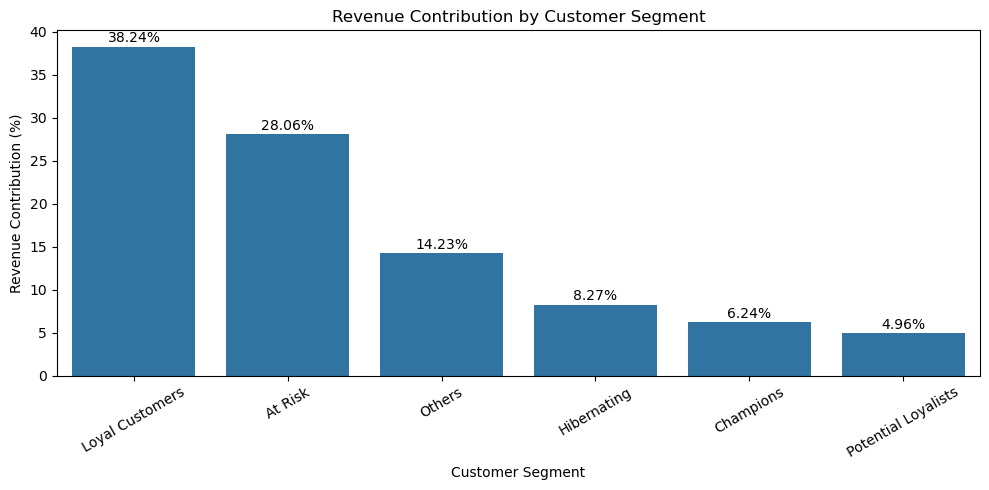

In [156]:
revenue_by_segment = (
    rfm_churn.groupby("Customer_Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

revenue_percentage = (
    revenue_by_segment / revenue_by_segment.sum()
) * 100

plt.figure(figsize=(10, 5))

sns.barplot(
    x=revenue_percentage.index,
    y=revenue_percentage.values
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")
plt.xticks(rotation=30)

for i, value in enumerate(revenue_percentage.values):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [157]:
segment_comparison = rfm_churn.groupby(
    "Customer_Segment"
).agg(
    Customer_Count=("customer_id", "count"),
    Total_Revenue=("Monetary", "sum")
)

segment_comparison["Customer_Percentage"] = (
    segment_comparison["Customer_Count"] /
    segment_comparison["Customer_Count"].sum()
) * 100

segment_comparison["Revenue_Percentage"] = (
    segment_comparison["Total_Revenue"] /
    segment_comparison["Total_Revenue"].sum()
) * 100

segment_comparison = segment_comparison.round(2)

segment_comparison

,Customer_Count,Total_Revenue,Customer_Percentage,Revenue_Percentage
Customer_Segment,,,,
At Risk,984,10056853.68,19.68,28.06
Champions,84,2234523.06,1.68,6.24
Hibernating,1012,2963045.44,20.24,8.27
Loyal Customers,1260,13701827.27,25.20,38.24
Others,953,5100847.28,19.06,14.23
Potential Loyalists,707,1777072.82,14.14,4.96


In [159]:
segment_comparison["Revenue_Index"] = (
    segment_comparison["Revenue_Percentage"] /
    segment_comparison["Customer_Percentage"]
).round(2)

segment_comparison.sort_values(
    by="Revenue_Index",
    ascending=False
)

,Customer_Count,Total_Revenue,Customer_Percentage,Revenue_Percentage,Revenue_Index
Customer_Segment,,,,,
Champions,84,2234523.06,1.68,6.24,3.71
Loyal Customers,1260,13701827.27,25.20,38.24,1.52
At Risk,984,10056853.68,19.68,28.06,1.43
Others,953,5100847.28,19.06,14.23,0.75
Hibernating,1012,2963045.44,20.24,8.27,0.41
Potential Loyalists,707,1777072.82,14.14,4.96,0.35


In [161]:
business_recommendations = pd.DataFrame({
    "Customer_Segment": [
        "Champions",
        "Loyal Customers",
        "At Risk",
        "Hibernating",
        "Potential Loyalists",
        "Others"
    ],
    "Business_Problem": [
        "Small but highly valuable group",
        "Need to maintain loyalty",
        "High historical revenue with declining activity",
        "High churn and low recent activity",
        "Recent customers with low transaction frequency",
        "Moderate engagement and revenue"
    ],
    "Recommended_Action": [
        "VIP rewards and personalized service",
        "Loyalty programs and exclusive benefits",
        "Personalized retention offers and outreach",
        "Win-back campaigns",
        "Onboarding and engagement campaigns",
        "Analyze behavior and encourage repeat purchases"
    ]
})

business_recommendations

,Customer_Segment,Business_Problem,Recommended_Action
0,Champions,Small but highly valuable group,VIP rewards and personalized service
1,Loyal Customers,Need to maintain loyalty,Loyalty programs and exclusive benefits
2,At Risk,High historical revenue with declining activity,Personalized retention offers and outreach
3,Hibernating,High churn and low recent activity,Win-back campaigns
4,Potential Loyalists,Recent customers with low transaction frequency,Onboarding and engagement campaigns
5,Others,Moderate engagement and revenue,Analyze behavior and encourage repeat purchases


Table containing all the important metrics.


In [162]:
dashboard_data = rfm_churn.groupby("Customer_Segment").agg(
    Customer_Count=("customer_id", "count"),
    Churned_Customers=("is_churned", "sum"),
    Churn_Rate=("is_churned", "mean"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

dashboard_data["Churn_Rate"] *= 100

dashboard_data["Customer_Percentage"] = (
    dashboard_data["Customer_Count"] /
    dashboard_data["Customer_Count"].sum()
) * 100

dashboard_data["Revenue_Percentage"] = (
    dashboard_data["Total_Revenue"] /
    dashboard_data["Total_Revenue"].sum()
) * 100

dashboard_data = dashboard_data.round(2)

dashboard_data

,Customer_Segment,Customer_Count,Churned_Customers,Churn_Rate,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage,Revenue_Percentage
0,At Risk,984,125.0,12.70,94.73,37.64,10220.38,10056853.68,19.68,28.06
1,Champions,84,0.0,0.00,3.06,52.46,26601.46,2234523.06,1.68,6.24
2,Hibernating,1012,530.0,52.37,411.10,10.76,2927.91,2963045.44,20.24,8.27
3,Loyal Customers,1260,0.0,0.00,10.18,45.35,10874.47,13701827.27,25.20,38.24
4,Others,953,1.0,0.10,12.36,19.85,5352.41,5100847.28,19.06,14.23
5,Potential Loyalists,707,0.0,0.00,6.20,9.65,2513.54,1777072.82,14.14,4.96


In [163]:
dashboard_data = dashboard_data.sort_values(
    by="Total_Revenue",
    ascending=False
).reset_index(drop=True)

dashboard_data

,Customer_Segment,Customer_Count,Churned_Customers,Churn_Rate,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage,Revenue_Percentage
0,Loyal Customers,1260,0.0,0.00,10.18,45.35,10874.47,13701827.27,25.20,38.24
1,At Risk,984,125.0,12.70,94.73,37.64,10220.38,10056853.68,19.68,28.06
2,Others,953,1.0,0.10,12.36,19.85,5352.41,5100847.28,19.06,14.23
3,Hibernating,1012,530.0,52.37,411.10,10.76,2927.91,2963045.44,20.24,8.27
4,Champions,84,0.0,0.00,3.06,52.46,26601.46,2234523.06,1.68,6.24
5,Potential Loyalists,707,0.0,0.00,6.20,9.65,2513.54,1777072.82,14.14,4.96


In [164]:
rfm_churn.to_csv(
    "rfm_customer_analysis.csv",
    index=False
)

In [165]:
dashboard_data.to_csv(
    "customer_segment_summary.csv",
    index=False
)

In [166]:
import os

print(os.path.exists("rfm_customer_analysis.csv"))
print(os.path.exists("customer_segment_summary.csv"))

True
True
